# Week 6a.1: Planning and Task Decomposition

Last week, we saw reflection works when the first query was simply the wrong wording.

Some questions are not a wording problem. They need two separate searches from the start, which isn't solved rewriting a single query.

We'll write a planner that breaks the question into steps, run the steps, and then deal with what happens when the plan itself is wrong.

### A compound question:

**I ordered on Saturday and want to return it. When does it ship, and how long until I see the refund?**

<img src="figures/planning.png" width="900">

The retriever is the same in both rows. The only change is the question provided to the retriever.

In [1]:
from dotenv import load_dotenv
import os

load_dotenv()
assert os.getenv("GOOGLE_API_KEY"), "No GOOGLE_API_KEY found."
print("API key loaded")

API key loaded


## 0. Model Setup

Execute one of the following to define the model.

In [3]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="qwen3.5:4b", reasoning=False)

In [ ]:
from langchain.chat_models import init_chat_model

model = init_chat_model(model="gpt-4.1-mini")

In [ ]:
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

Pick the same embedding model you used in Week 5.

In [ ]:
from langchain_google_genai import GoogleGenerativeAIEmbeddings

embeddings = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")

In [4]:
from langchain_ollama import OllamaEmbeddings

embeddings = OllamaEmbeddings(model="qwen3-embedding:0.6b")

In [ ]:
from langchain_openai import OpenAIEmbeddings

embeddings = OpenAIEmbeddings(
    model="liquid/lfm-2.5-embedding-350m:free",
    base_url="https://openrouter.ai/api/v1",
    api_key=os.environ["OPENROUTER_API_KEY"],
    check_embedding_ctx_length=False,
)

In [ ]:
from langchain_nvidia_ai_endpoints import NVIDIAEmbeddings

embeddings = NVIDIAEmbeddings(model="nvidia/nemotron-3-embed-1b")

## 1. When one search isn't enough

In [5]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.vectorstores import InMemoryVectorStore

policy = open("husky_policy.md").read()
chunks = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=0).split_text(policy)
store = InMemoryVectorStore.from_texts(chunks, embeddings)

print(f"{len(chunks)} chunks indexed")

6 chunks indexed


In [6]:
question = ("I ordered on Saturday and want to return it. "
            "When does it ship, and how long until I see the refund?")

for h in store.similarity_search(question, k=3):
    print("-", " ".join(h.page_content.split())[:110], "\n")

- # Husky Tech Customer Policy ## 1. Returns ### 1.1 Standard return window Items purchased from Husky Tech may  

- Return shipping is free for orders over $50. For orders under $50, a $6.99 return shipping fee is deducted fro 

- ### 1.3 Damaged, defective, and dead-on-arrival items The 30-day window described in section 1.1 does not appl 



Two questions in one sentence. The passages that come back are all about returns and refunds.

The weekend shipping rule is in section 2, and it is not here. 

Raising `k` to 3 did not bring it in either, because the sentence that matters is not similar to the question as a whole. It is similar to half of it.

## 2. Planning and Decomposition

The planner breaks one question into several questions, which is referred to as task decomposition.

The idea behind planning comes from where the operation sits. `planning` will be the first node in the graph. It runs before any search, and what it writes to state is `steps`, which every node after it reads.

To implement this, rather than search with the question, we'll ask the model what searches the question needs.
 - Using `with_structured_output`, we will specify the plan as a list we can loop over.

In [7]:
from pydantic import BaseModel, Field


class Plan(BaseModel):
    """The searches needed to answer the customer."""

    steps: list[str] = Field(
        description="Each step is one question to search the policy with")


planner = model.with_structured_output(Plan)

PLAN_PROMPT = """A customer asked: {question}

The policy is searched one question at a time, and a search returns the two
passages closest in meaning to whatever is asked.

Break this into the separate searches needed to answer it. Each step is one
plain question. Keep it to the fewest steps that cover the question."""

In [11]:
plan = planner.invoke(PLAN_PROMPT.format(question=question))
plan.steps

['When does an item ordered on Saturday ship?',
 'How long until I see my refund?']

Two steps, one per half of the question. Each is a question that can be actually answered by a search.

That placement has a cost. The planner picks what to search for without having seen a passage. 

Run it on two questions this policy cannot answer:

In [9]:
questions = ["Do you gift wrap, and can I add a handwritten note to the box?",
          "What is your policy on cryogenic shipping of live tissue samples?"]
 
for q in questions:
    print(q)
    plan = planner.invoke(PLAN_PROMPT.format(question=q))

    for step in plan.steps:
        print(f"   - {step}")
    print()

Do you gift wrap, and can I add a handwritten note to the box?
   - Do you offer gift wrapping services?
   - Is it possible to include a handwritten note with an order?

What is your policy on cryogenic shipping of live tissue samples?
   - What is your shipping policy for live tissue samples?
   - Do you offer cryogenic shipping services?



In [ ]:
plan

Both plans look as reasonable as the one above. The policy has four sections, and neither gift wrapping nor tissue samples is in any of them. The planner had no way to know, because it had not looked.

The placement also buys something. `steps` is in state, so a later node can rewrite it. A decomposition done inline, inside `retrieve`, leaves nothing to revise, though.

### Findings from steps
A step is a question, and searching with it returns passages. We will want to keep the two together, so a finding is a pair.

In [10]:
step = plan.steps[0]
passages = [h.page_content for h in store.similarity_search(step, k=2)]

(step, passages)

('What is your shipping policy for live tissue samples?',
 ['Customers reporting damage should be asked for the order number and a short\ndescription of the fault. No photograph is required.\n\n## 2. Shipping\n\nStandard shipping takes 3 to 5 business days within the continental United\nStates. Expedited shipping arrives in 1 to 2 business days for $14.99. We do not\ncurrently ship outside the United States.',
  '### 1.3 Damaged, defective, and dead-on-arrival items\n\nThe 30-day window described in section 1.1 does not apply to items that arrive\ndamaged or that fail due to a manufacturing defect. Such items may be returned\nat any point during the one-year manufacturer warranty, and Husky Tech covers\nreturn shipping in full regardless of order value.'])

`(step, passages)`.

The review has to decide whether every part of the question is covered, and to do that it needs to know which part each passage was fetched for. The replan has to list what has already been searched.


In [12]:
findings = []

#TODO: construct findings (step, passages)

for step in plan.steps:
    passages = [h.page_content for h in store.similarity_search(step, k=2)]
    findings.append((step, passages))


In [13]:
findings

[('When does an item ordered on Saturday ship?',
  ['Orders placed after 2pm ET ship the following business day. Orders placed on a\nweekend ship on the next Monday.\n\n## 3. Warranty\n\nAll Husky Tech electronics include a one-year manufacturer warranty covering\ndefects in materials and workmanship. The warranty does not cover accidental\ndamage, liquid damage, or normal wear such as frayed cables.',
   'Customers reporting damage should be asked for the order number and a short\ndescription of the fault. No photograph is required.\n\n## 2. Shipping\n\nStandard shipping takes 3 to 5 business days within the continental United\nStates. Expedited shipping arrives in 1 to 2 business days for $14.99. We do not\ncurrently ship outside the United States.']),
 ('How long until I see my refund?',
  ['Return shipping is free for orders over $50. For orders under $50, a $6.99\nreturn shipping fee is deducted from the refund.\n\n### 1.2 Items that cannot be returned\n\nOpened software, digital 

In [16]:
{step for step, _ in findings or []}


{'How long until I see my refund?',
 'When does an item ordered on Saturday ship?'}

## 3. State

`findings` accumulates using the same reducer from last week. 

Each entry is a step and the associated passages.

In [14]:
import operator
from typing import Annotated, Literal, TypedDict


class PlanState(TypedDict):
    question: str
    steps: list                                 # the current plan
    findings: Annotated[list, operator.add]     # (step, passages), accumulates
    new_searches: int                           # searches this round that were not repeats
    missing: str
    verdict: str
    replans: int
    answer: str

## 4. The nodes

Given a plan, `execute` runs every step in the current plan. `synthesize` writes one answer from everything collected.

In [15]:
K = 2

CAVEAT = "Say plainly what you could not confirm."

ANSWER_PROMPT = """Answer the customer using only the passages below.
{caveat}

{evidence}

CUSTOMER: {question}"""


def format_findings(findings: list) -> str:
    """Lay the (step, passages) pairs out as text for a prompt."""
    return "\n\n".join(f"STEP: {step}\n" + "\n".join(passages)
                       for step, passages in findings)


def make_plan(state: PlanState) -> dict:
    plan_prompt = PLAN_PROMPT.format(question=state["question"])

    plan = planner.invoke(plan_prompt)
    return {"steps": plan.steps}

### `execute`

It runs the steps in the current plan and returns what they found. 
- It has to avoid repeating a search, and it has to report how much it actually did.

```
for each step in the current plan:
    if we have already searched this step, skip it
    otherwise search, and keep (step, passages)

return the new pairs, and how many there were
```

**Why skip a step.** `replan` can hand back a search from an earlier round. Running it again returns the identical passages and teaches nothing, so `already_run` is built from the steps in `findings` and used to pass over them.

**Why `new_searches`.** The node reports how many steps it ran *this round*. `decide` reads it: a round that ran nothing cannot change the evidence, only the verdict on it, so the loop stops instead of spending another replan. Without this the graph can spin until the cap on a plan it is no longer improving.

In [ ]:
def execute(state: PlanState) -> dict:
    # TODO
    already_run = {step for step, _ in state.get("findings") or []}

    found = []

    for step in state["steps"]:
        if step in already_run:
            continue

        hits = store.similarity_search(step, k=K)
        passages = [h.page_content for h in hits]
        found.append((step, passages))
        
    return {"findings": found, "new_searches": len(found)}

In [18]:
def synthesize(state: PlanState) -> dict:
    evidence = format_findings(state["findings"])
    caveat = "" if state.get("verdict") == "sufficient" else CAVEAT
    answer_prompt = ANSWER_PROMPT.format(caveat=caveat,
                                         evidence=evidence,
                                         question=state["question"])

    answer = model.invoke(answer_prompt).text.strip()
    return {"answer": answer}

## 5. Plan, execute, answer

Three nodes in a line. No loop yet.

In [22]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(PlanState)

#TODO make_plan -> execute -> synthesize
builder.add_node("make_plan", make_plan)
builder.add_node("execute", execute)
builder.add_node("synthesize", synthesize)

builder.add_edge(START, "make_plan")
builder.add_edge("make_plan", "execute")
builder.add_edge("execute", "synthesize")
builder.add_edge("synthesize", END)

planner_agent = builder.compile()

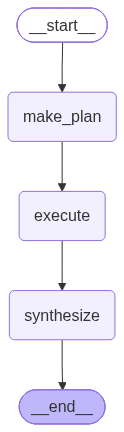

In [20]:
from IPython.display import Image, display

display(Image(planner_agent.get_graph().draw_mermaid_png()))

In [23]:
result = planner_agent.invoke({"question": question})

In [24]:
result

{'question': 'I ordered on Saturday and want to return it. When does it ship, and how long until I see the refund?',
 'steps': ['What is the shipping schedule for orders placed on Saturday?',
  'How long does it take for a refund to appear after I submit a return?'],
 'findings': [('What is the shipping schedule for orders placed on Saturday?',
   ['Customers reporting damage should be asked for the order number and a short\ndescription of the fault. No photograph is required.\n\n## 2. Shipping\n\nStandard shipping takes 3 to 5 business days within the continental United\nStates. Expedited shipping arrives in 1 to 2 business days for $14.99. We do not\ncurrently ship outside the United States.',
    'Orders placed after 2pm ET ship the following business day. Orders placed on a\nweekend ship on the next Monday.\n\n## 3. Warranty\n\nAll Husky Tech electronics include a one-year manufacturer warranty covering\ndefects in materials and workmanship. The warranty does not cover accidental\n

In [25]:
for step, passages in result["findings"]:
    print(f"STEP: {step}")
    for p in passages:
        print("   ", " ".join(p.split())[:88])
    print()
print(result["answer"])

STEP: What is the shipping schedule for orders placed on Saturday?
    Customers reporting damage should be asked for the order number and a short description 
    Orders placed after 2pm ET ship the following business day. Orders placed on a weekend s

STEP: How long does it take for a refund to appear after I submit a return?
    # Husky Tech Customer Policy ## 1. Returns ### 1.1 Standard return window Items purchase
    Return shipping is free for orders over $50. For orders under $50, a $6.99 return shippi

Orders placed on Saturday ship the next Monday. For returns, refunds appear within 5 business days of the item arriving at our warehouse, provided the return is processed within the standard 30-day window and shipping fees have been accounted for. If you ordered software, digital codes, or redeemed gift cards on Saturday, note that these cannot be returned at all.


Both halves answered, from two searches that each saw what they needed.

The weekend rule came back this time. Nothing about the retriever changed.

## 6. Reviewing the plan
A planner can miss a step. 

Nothing downstream notices, because `execute` runs whatever it is given and `synthesize` writes from whatever it finds.

We can address this limitation by adding a review node, which use a reflection mechanism, and a `replan` node that writes the searches still needed.

<img src="figures/replanning.png" width="940">

The chain from section 5 is the top row. Everything below it is new.

`review` reads what `execute` found and decides whether the question is covered. If it is not, `replan` writes the searches still missing and hands them back to `execute`, which is the loop. If it is, or if we have run out of room to try, `synthesize` writes the answer from whatever we have.

In [26]:
class Review(BaseModel):
    """Evaluate whether the findings so far answer the customer."""

    sufficient: bool = Field(
        description="True only if every part of the question is covered")
    missing: str = Field(
        description="If not, which part is still unanswered, in a few words")


reviewer = model.with_structured_output(Review)


REVIEW_PROMPT = """A customer asked: {question}

Searches run so far and what they returned:

{evidence}

Is every part of the question covered by these passages?
Judge the passages, not the customer."""


In [27]:
MAX_REPLANS = 2

REPLAN_PROMPT = """A customer asked: {question}

These searches were already run:
{already}

Still missing: {missing}

Write the additional searches needed. Each one is a plain question, the same
as the steps above. Do not repeat a search already run."""

In [28]:
def review(state: PlanState) -> dict:
    evidence = format_findings(state["findings"])
    review_prompt = REVIEW_PROMPT.format(question=state["question"],
                                         evidence=evidence)

    verdict = reviewer.invoke(review_prompt)
    return {"verdict": "sufficient" if verdict.sufficient else "insufficient",
            "missing": verdict.missing}


def replan(state: PlanState) -> dict:
    already = "\n".join(f"- {step}" for step, _ in state["findings"])
    replan_prompt = REPLAN_PROMPT.format(question=state["question"],
                                         already=already,
                                         missing=state["missing"])

    revised_plan = planner.invoke(replan_prompt)
    return {"steps": revised_plan.steps,
            "replans": state.get("replans", 0) + 1}


def decide(state: PlanState) -> Literal["replan", "synthesize"]:
    if state["verdict"] == "sufficient":
        return "synthesize"
    if state.get("replans", 0) >= MAX_REPLANS:
        return "synthesize"
    if state.get("new_searches", 1) == 0:   # the replan gave us nothing we had not run
        return "synthesize"
    return "replan"

## 7. The graph with replanning

`replan -> execute` points backwards, the same way `rewrite_query -> retrieve` did on Friday. The difference is what gets revised: a query there, a plan here.

In [29]:
builder = StateGraph(PlanState)
builder.add_node("make_plan", make_plan)
builder.add_node("execute", execute)
builder.add_node("review", review)
builder.add_node("replan", replan)
builder.add_node("synthesize", synthesize)

# TODO
builder.add_edge(START, "make_plan")
builder.add_edge("make_plan", "execute")
builder.add_edge("execute", "review")
builder.add_conditional_edges("review",decide)
builder.add_edge("replan", "execute")
builder.add_edge("synthesize", END)

replanning_agent = builder.compile()

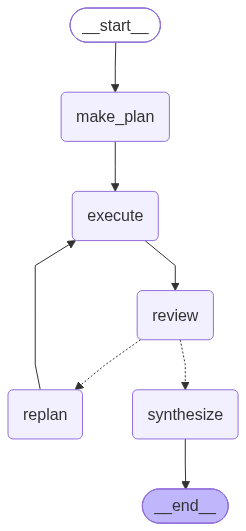

In [30]:
display(Image(replanning_agent.get_graph().draw_mermaid_png()))

Before we break anything, let's test the same question as before:

In [31]:
result = replanning_agent.invoke({"question": question})

print(f"replans: {result.get('replans', 0)}   verdict: {result['verdict']}")
for step, _ in result["findings"]:
    print("searched:", step)
print()
print(result["answer"])

replans: 1   verdict: sufficient
searched: When does an order placed on Saturday ship?
searched: How long until I see a refund?
searched: When does a returned item ship from Husky Tech?
searched: How long until I see the refund after returning an item?

If you ordered your item on Saturday, it will ship on the following Monday. Regarding the refund, once the returned item arrives at our warehouse, refunds are issued within 5 business days. Note that if your order was under $50, a $6.99 return shipping fee is deducted from the refund; otherwise, return shipping is free for orders over $50.


Same answer as section 5, and `replans` is 0. The review agreed with the plan, so `replan` never ran.

A loop that does nothing when nothing is wrong is desired behavior. 

Let's try to ask a question that may lead to replanning.

## 8. A question the policy cannot finish

The planner is good at splitting a question. On a document this small it is hard to make it drop a part.

The failure you will actually meet is the other one. The plan is right, and one of its steps asks for a rule the policy never states. `review` cannot tell those two cases apart. It reports a part of the question as uncovered, and `replan` goes looking for a rule that does not exist.

In [32]:
unanswerable = "Can I return my headphones, and do you offer gift wrapping?"

In [33]:
result = replanning_agent.invoke({"question": unanswerable})


In [34]:
result

{'question': 'Can I return my headphones, and do you offer gift wrapping?',
 'steps': ['Can I return my headphones?', 'Do you offer gift wrapping?'],
 'findings': [('Can I return my headphones?',
   ['Return shipping is free for orders over $50. For orders under $50, a $6.99\nreturn shipping fee is deducted from the refund.\n\n### 1.2 Items that cannot be returned\n\nOpened software, digital download codes, and redeemed gift cards are not\nreturnable under any circumstances. Earbuds and in-ear headphones may only be\nreturned if the hygiene seal is unbroken.',
    '# Husky Tech Customer Policy\n\n## 1. Returns\n\n### 1.1 Standard return window\n\nItems purchased from Husky Tech may be returned within 30 days of delivery for a\nfull refund to the original payment method. The item must be in its original\npackaging with all included accessories. Refunds are issued within 5 business\ndays of the returned item arriving at our warehouse.']),
  ('Do you offer gift wrapping?',
   ['Return shi

In [35]:
print(result["answer"])

I can return your headphones if they were opened less than 30 days after delivery, kept in their original packaging with all accessories, and (if they are earbuds or in-ear headphones) the hygiene seal is unbroken. Please note that return shipping for orders under $50 will cost $6.99; it is free if your order was over $50.

Regarding gift wrapping, the provided text does not mention this service being offered.


In [36]:
state = {"question": unanswerable, "steps": [], "findings": [],
         "missing": "", "verdict": "", "replans": 0, "answer": ""}

for update in replanning_agent.stream(state, stream_mode="updates"):
    for node, change in update.items():
        if node == "make_plan":
            print(f"plan: {change['steps']}")
        elif node == "execute":
            for step, _ in change["findings"]:
                print(f"  searched: {step}")
        elif node == "review":
            tail = f" \u2014 missing: {change['missing']}" if change["verdict"] == "insufficient" else ""
            print(f"  reviewed: {change['verdict']}{tail}")
        elif node == "replan":
            print(f"  replan {change['replans']}: {change['steps']}")
        elif node == "synthesize":
            answer = change["answer"]

print()
print(answer)

plan: ['Can I return my headphones?', 'Do you offer gift wrapping?']
  searched: Can I return my headphones?
  searched: Do you offer gift wrapping?
  reviewed: sufficient

Earbuds and in-ear headphones may only be returned if the hygiene seal is unbroken. Regarding gift wrapping, the provided text does not mention that service.


Both replans go hunting for a gift-wrapping rule, and the cap is the only thing that stops it. 

`synthesize` then runs with `verdict` still `insufficient`, so `CAVEAT` goes into the prompt and the answer has to say what it could not confirm.

`"When does my order ship, and can I change the delivery address after ordering?"` has the same shape.

This is the limit of a reviewer that only checks coverage:
- It can see that a part of the question is unanswered. 
- It cannot see whether that is because the plan was wrong or because the document does not say.

## 9. A plan that is missing a step

Section 8 showed the loop running and getting nowhere, because the policy had nothing to find.

Here is the other case: the plan is short, and the document does have the answer.

The customer asks one thing. Two rules decide it, and the planner only looks for one.

In [37]:
opened = "I opened my earbuds and want a refund. What happens?"

for step in replanning_agent.stream({"question": opened}, stream_mode="updates"):
    for node, update in step.items():
        if node == "make_plan":
            print(f"plan: {update['steps']}")
        elif node == "execute":
            for q, _ in update["findings"]:
                print(f"  searched: {q}")
        elif node == "review":
            tail = f" \u2014 missing: {update['missing']}" if update["verdict"] == "insufficient" else ""
            print(f"  reviewed: {update['verdict']}{tail}")
        elif node == "replan":
            print(f"  replan {update['replans']}: {update['steps']}")
        elif node == "synthesize":
            answer = update["answer"]

print()
print(answer)

plan: ['What does the return policy state for opened earbuds?', 'Is a refund available for opened earbuds if the policy is met?']
  searched: What does the return policy state for opened earbuds?
  searched: Is a refund available for opened earbuds if the policy is met?
  reviewed: insufficient — missing: The provided passages do not cover what happens when a customer opens their earbuds. The policy states that items like earbuds can only be returned if the hygiene seal is unbroken, but it does not explain the outcome or consequences if the seal has been broken (e.g., whether they can return them at all, if they are eligible for any credit, or what alternative remedies exist). The fact that the customer 'opened' them implies the seal may have been compromised, which contradicts the condition for a standard refund found in the text. Therefore, the full answer to 'what happens?' cannot be derived from the passages.
  replan 1: ['What are the consequences of opening earbuds that have been

The plan has one step, and it is not wrong, only short. Section 1.1 holds the refund window, which is what it searched for. Section 1.2 says earbuds may only be returned if the hygiene seal is unbroken, and nothing in the customer's question said the words *hygiene seal*.

Run it a few times, because this one goes two ways.

Usually the review notices the gap, the replan writes the search that closes it, and the second pass finds the rule. Sometimes the single search pulls both sections at once, the review says `sufficient`, and no replan happens at all. Both are correct. `k=2` is two passages, and whether those two happen to include 1.2 depends on how the planner worded its one step.

A plan is a guess made before any evidence has been seen. This one is a reasonable guess that is sometimes lucky.

## 10. Two loops, two things being revised

| | revises | when |
|---|---|---|
| Friday's reflection | the query | one search came back short |
| Today's replanning | the plan | the whole question is not covered |

Reflection fixes a wording problem. Replanning fixes a decomposition problem. A system that only rewrites queries will loop forever on a question that needed two searches.

## 11. Putting it behind a tool

The planner is a retriever. The support agent from Week 5 already has one, and swapping it is the same process.

**We need to make one change first.** 

This graph ends with `synthesize`, which writes prose. 

The support agent writes the prose. 

If both of them do it, two models are drafting the same reply, so we compile the same nodes without that last step.

In [38]:
def stop_or_replan(state: PlanState) -> Literal["replan", "__end__"]:
    if state["verdict"] == "sufficient":
        return "__end__"
    if state.get("replans", 0) >= MAX_REPLANS:
        return "__end__"
    if state.get("new_searches", 1) == 0:
        return "__end__"
    return "replan"


searcher = StateGraph(PlanState)
searcher.add_node("make_plan", make_plan)
searcher.add_node("execute", execute)
searcher.add_node("review", review)
searcher.add_node("replan", replan)

searcher.add_edge(START, "make_plan")
searcher.add_edge("make_plan", "execute")
searcher.add_edge("execute", "review")
searcher.add_conditional_edges("review", stop_or_replan)
searcher.add_edge("replan", "execute")

plan_search = searcher.compile()

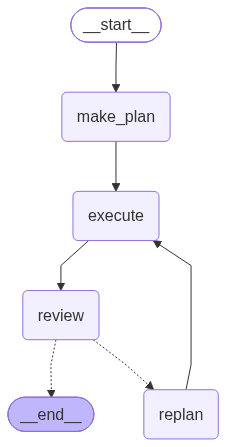

In [39]:
display(Image(plan_search.get_graph().draw_mermaid_png()))

In [40]:
from langchain.tools import tool

GAP_NOTE = """NOTE: the policy search ran {rounds} rounds and still did not find a rule
that settles this ({missing}). The search coming up empty is not proof the policy is
silent, and a silent policy would not mean no. Do not tell the customer that Husky Tech
does or does not do this, and do not fill the gap from memory. This is a question the
tools cannot resolve."""


@tool
def search_policy(question: str) -> str:
    """Search the Husky Tech written policy and return the passages most relevant to a
    question. Use this for any question about returns, shipping, warranty or support
    hours. Returns policy text, not an answer: read it and decide."""
    result = plan_search.invoke({"question": question})
    passages = format_findings(result["findings"])

    if result["verdict"] == "sufficient":
        return passages

    note = GAP_NOTE.format(rounds=result.get("replans", 0) + 1,
                           missing=result["missing"][:120])
    return passages + "\n\n---\n\n" + note

The agent is the one from W05b.2, with the same state, same nodes, same edges, and same tool list.

In [41]:
from support_tools import (look_up_order, check_return_eligibility,
                            escalate_to_human, SYSTEM_PROMPT)
from langchain.messages import SystemMessage, HumanMessage
from langgraph.graph import MessagesState
from langgraph.prebuilt import ToolNode, tools_condition

sys_msg = SystemMessage(content=SYSTEM_PROMPT)
TOOLS = [look_up_order, check_return_eligibility, search_policy, escalate_to_human]
model_with_tools = model.bind_tools(TOOLS)


def assistant(state: MessagesState) -> dict:
    return {"messages": [model_with_tools.invoke([sys_msg] + state["messages"])]}


agent = StateGraph(MessagesState)
agent.add_node("assistant", assistant)
agent.add_node("tools", ToolNode(TOOLS))
agent.add_edge(START, "assistant")
agent.add_conditional_edges("assistant", tools_condition)
agent.add_edge("tools", "assistant")

support_agent = agent.compile()

In [ ]:
updated_question = "Can I return my fraying cables. My order ID is HT-1004"
result = support_agent.invoke({"messages": [HumanMessage(content=updated_question)]})

called = [tc["name"] for m in result["messages"]
          for tc in (getattr(m, "tool_calls", None) or [])]
print("tools called:", called)
print()
print(result["messages"][-1].text)

tools called: []

I would be happy to help you with that. However, I need your order ID (e.g., HT-1001) to look up the specific details of your order and tell you when it ships. You can find this in your confirmation email.

Additionally, to give you an accurate timeframe for when you'll see the refund once it's shipped, could you please confirm if you purchased the item within the last 30 days? This helps me check your eligibility for the return policy.


## 12. Things to try

1. Ask a three-part question, such as one that also asks what return shipping costs. Does the planner produce three steps, and do all three retrieve something useful?

2. Set `MAX_REPLANS = 0` and run section 8 again. What does the answer say, and is it honest about what is missing?

3. Give the planner a question the policy cannot answer at all, such as whether you can track a return. How many replans does it burn before giving up, and is that the behavior you want?

4. The plan is made once, before anything is retrieved. Change `make_plan` so it sees the first two passages for the question before planning. Does the plan get better, and what does it cost?

In [ ]:
# your experiments here